# Lab 5

LSTMs for classification tasks  
By Alex Horyshevskyi  

### Installing dependencies

In [27]:
%pip install keras numpy scikit-learn transformers matplotlib --quiet
%pip install torch --index-url https://download.pytorch.org/whl/cu130 --quiet

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


### GPU check

In [28]:
import os
os.environ["KERAS_BACKEND"] = "torch"

In [29]:
import keras
import torch


print(f"Using Keras version: {keras.__version__}")
print(f"Using PyTorch version: {torch.__version__}")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Computation will be performed on: {device}")

Using Keras version: 3.13.2
Using PyTorch version: 2.10.0+cu130
Computation will be performed on: cuda


### Importing libraries

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

from keras.models import Model, Sequential
from keras.layers import (
    LSTM, Activation, Dense, Dropout, Input, Embedding,
    Conv1D, MaxPooling1D, BatchNormalization, Bidirectional,
)
from keras.optimizers import RMSprop
from keras.callbacks import EarlyStopping
from keras.preprocessing.sequence import pad_sequences

from transformers import AutoTokenizer

### Data loading and preprocessing

In [31]:
df = pd.read_csv('./spam.csv',delimiter=',',encoding='latin-1')
df.head()

df = df.drop(['Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'], axis=1)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   v1      5572 non-null   object
 1   v2      5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


Text(0.5, 1.0, 'Number of ham and spam messages')

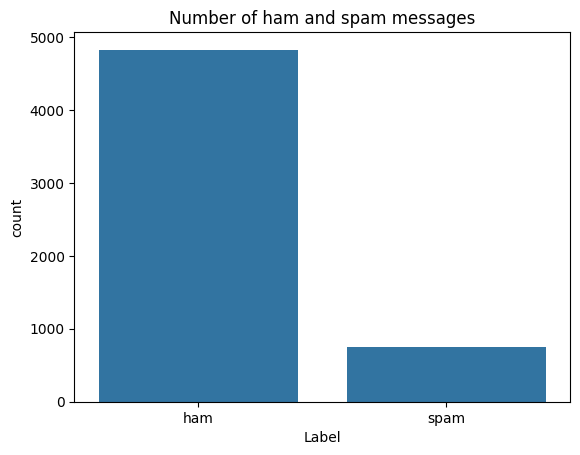

In [32]:
sns.countplot(x='v1', data=df)
plt.xlabel('Label')
plt.title('Number of ham and spam messages')

## Usecase 1: Simple LSTM for text classification

### Text tokenization and vectorization

In [33]:
tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")

# Get the actual vocabulary size from the tokenizer to feed into the Embedding layer
vocab_size = tokenizer.vocab_size 
max_len = 500

### Create input and output sequences

In [34]:
X = df.v2
Y = df.v1

le = LabelEncoder()
Y = np.asarray(le.fit_transform(Y)).reshape(-1, 1)

# Розділення датсету на дані для навчання та для валідації
X_train, X_test_val, Y_train, Y_test_val = train_test_split(X, Y, test_size=0.3, random_state=42)
X_val, X_test, Y_val, Y_test = train_test_split(X_test_val, Y_test_val, test_size=0.5, random_state=42)

train_encodings = tokenizer(
    X_train.tolist(), 
    truncation=True,        # Cuts off reviews longer than max_len
    padding='max_length',   # Pads reviews shorter than max_len with 0s
    max_length=max_len, 
    return_tensors='np'     
)

val_encodings = tokenizer(
    X_val.tolist(), 
    truncation=True, 
    padding='max_length', 
    max_length=max_len, 
    return_tensors='np'
)

test_encodings = tokenizer(
    X_test.tolist(),
    truncation=True, 
    padding='max_length', 
    max_length=max_len, 
    return_tensors='np'
)


X_train_vec = train_encodings['input_ids']
X_val_vec = val_encodings['input_ids']
X_test_vec = test_encodings['input_ids']

### RNN architecture and training

In [35]:
def RNN(max_words: int, max_len: int):
    inputs = Input(name="inputs", shape=[max_len])
    layer = Embedding(max_words, 50)(inputs)
    layer = LSTM(64)(layer)
    layer = Dense(256, name="FC1")(layer)
    layer = Activation("relu")(layer)
    layer = Dropout(0.5)(layer)
    layer = Dense(1, name="out_layer")(layer)
    layer = Activation("sigmoid")(layer)
    model = Model(inputs=inputs, outputs=layer)
    model.compile(loss="binary_crossentropy", optimizer=RMSprop(), metrics=["accuracy"])
    model.summary()
    return model

In [36]:
model = RNN(vocab_size, max_len)
model.fit(
    X_train_vec,
    np.asarray(Y_train).astype("float32"),
    batch_size=128,
    epochs=10,
    validation_data=(
        X_val_vec,
        np.asarray(Y_val).astype("float32"),
    ),
    callbacks=[EarlyStopping(monitor="val_loss", patience=3)],
)

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ inputs (InputLayer)             │ (None, 500)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_7 (Embedding)         │ (None, 500, 50)        │     1,526,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_6 (LSTM)                   │ (None, 64)             │        29,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ FC1 (Dense)                     │ (None, 256)            │        16,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ out_layer (Dense)               │ (None, 1)              │           257 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 1)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,572,437 (6.00 MB)

 Trainable params: 1,572,437 (6.00 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 21s 676ms/step - accuracy: 0.8513 - loss: 0.4460 - val_accuracy: 0.8720 - val_loss: 0.3835
Epoch 2/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 20s 662ms/step - accuracy: 0.8646 - loss: 0.4016 - val_accuracy: 0.8720 - val_loss: 0.3826
Epoch 3/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 20s 663ms/step - accuracy: 0.8646 - loss: 0.4059 - val_accuracy: 0.8720 - val_loss: 0.3855
Epoch 4/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 20s 664ms/step - accuracy: 0.8646 - loss: 0.4029 - val_accuracy: 0.8720 - val_loss: 0.3869
Epoch 5/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 21s 676ms/step - accuracy: 0.8646 - loss: 0.4022 - val_accuracy: 0.8720 - val_loss: 0.3826
Epoch 6/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 21s 676ms/step - accuracy: 0.8646 - loss: 0.4039 - val_accuracy: 0.8720 - val_loss: 0.3923
Epoch 7/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 21s 667ms/step - accuracy: 0.8646 - loss: 0.4029 - val_accuracy: 0.8720 - val_loss: 0.3828
Epoch 8/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 20s 651ms/step - accuracy: 0.8646 - loss: 0.4016 - val_accu

### Evaluation on test set

In [37]:
test_loss, test_acc = model.evaluate(X_test_vec, Y_test)
print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_acc:.4f}")

27/27 ━━━━━━━━━━━━━━━━━━━━ 10s 366ms/step - accuracy: 0.8660 - loss: 0.3939
Test Loss: 0.3939, Test Accuracy: 0.8660


### Use Case 1: Experiments with Different Network Parameters

We vary LSTM units, embedding dimension, FC layer size, and dropout rate across four configurations.  
Config 2 (highlighted in orange) is the baseline from the original model above.

In [ ]:
# Experiment: vary LSTM units, embedding dim, FC size, dropout rate
configs = [
    {'lstm_units': 32,  'emb_dim': 32, 'fc_units': 128, 'dropout': 0.3},
    {'lstm_units': 64,  'emb_dim': 50, 'fc_units': 256, 'dropout': 0.5},   # baseline
    {'lstm_units': 128, 'emb_dim': 64, 'fc_units': 256, 'dropout': 0.3},
    {'lstm_units': 128, 'emb_dim': 64, 'fc_units': 512, 'dropout': 0.5},
]

results_uc1 = []
for cfg in configs:
    inputs = Input(name="inputs", shape=[max_len])
    layer  = Embedding(vocab_size, cfg['emb_dim'])(inputs)
    layer  = LSTM(cfg['lstm_units'])(layer)
    layer  = Dense(cfg['fc_units'], name="FC1")(layer)
    layer  = Activation("relu")(layer)
    layer  = Dropout(cfg['dropout'])(layer)
    layer  = Dense(1, name="out_layer")(layer)
    layer  = Activation("sigmoid")(layer)
    m = Model(inputs=inputs, outputs=layer)
    m.compile(loss="binary_crossentropy", optimizer=RMSprop(), metrics=["accuracy"])
    m.fit(
        X_train_vec, np.asarray(Y_train).astype("float32"),
        batch_size=128, epochs=10,
        validation_data=(X_val_vec, np.asarray(Y_val).astype("float32")),
        callbacks=[EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)],
        verbose=0,
    )
    loss, acc = m.evaluate(X_test_vec, Y_test, verbose=0)
    label = (f"LSTM={cfg['lstm_units']}, emb={cfg['emb_dim']}, "
             f"FC={cfg['fc_units']}, drop={cfg['dropout']}")
    results_uc1.append({'config': label, 'loss': round(loss, 4), 'accuracy': round(acc, 4)})
    print(f"{label}  ->  Test Acc: {acc:.4f}")

LSTM=32, emb=32, FC=128, drop=0.3  →  Test Acc: 0.8660
LSTM=64, emb=50, FC=256, drop=0.5  →  Test Acc: 0.8660
LSTM=128, emb=64, FC=256, drop=0.3  →  Test Acc: 0.8660
LSTM=128, emb=64, FC=512, drop=0.5  →  Test Acc: 0.8660


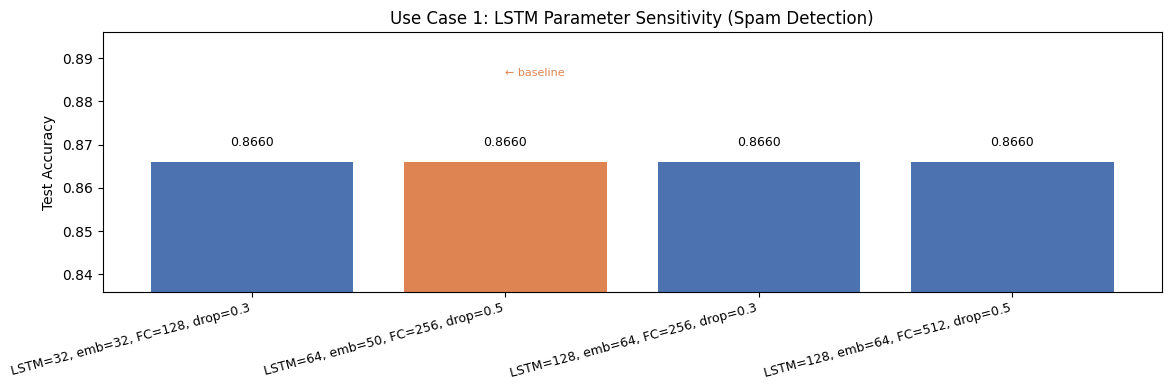

,config,loss,accuracy
0,"LSTM=32, emb=32, FC=128, drop=0.3",0.3943,0.866
1,"LSTM=64, emb=50, FC=256, drop=0.5",0.3939,0.866
2,"LSTM=128, emb=64, FC=256, drop=0.3",0.3945,0.866
3,"LSTM=128, emb=64, FC=512, drop=0.5",0.3957,0.866


In [39]:
labels_uc1 = [r['config'] for r in results_uc1]
accs_uc1   = [r['accuracy'] for r in results_uc1]
colors_uc1 = ['#DD8452' if i == 1 else '#4C72B0' for i in range(len(labels_uc1))]

fig, ax = plt.subplots(figsize=(12, 4))
bars = ax.bar(range(len(labels_uc1)), accs_uc1, color=colors_uc1)
ax.set_xticks(range(len(labels_uc1)))
ax.set_xticklabels(labels_uc1, rotation=15, ha='right', fontsize=9)
ax.set_ylim(min(accs_uc1) - 0.03, min(max(accs_uc1) + 0.03, 1.0))
ax.set_ylabel('Test Accuracy')
ax.set_title('Use Case 1: LSTM Parameter Sensitivity (Spam Detection)')
ax.text(1, max(accs_uc1) + 0.02, '← baseline', fontsize=8, color='#DD8452')
for bar, acc in zip(bars, accs_uc1):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.003,
            f'{acc:.4f}', ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()

pd.DataFrame(results_uc1)

## Use case 2. LSTM, LSTM + Dropout, LSTM + CNN for movie review classification

### Importing the IMDb dataset

In [40]:
from keras.datasets import imdb


# load the dataset but only keep the top n words, zero the rest
top_words = 5_000
(X_train, y_train), (X_test, y_test) = imdb.load_data(num_words=top_words)

# truncate and pad input sequences
max_review_length = 150
X_train = pad_sequences(X_train, maxlen=max_review_length)
X_test = pad_sequences(X_test, maxlen=max_review_length)

### LSTM architecture and training

In [41]:
embedding_vecor_length = 32

# create the model
model = Sequential()
model.add(Embedding(top_words, embedding_vecor_length))
model.add(LSTM(32))
model.add(Dense(1, activation='sigmoid'))
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
print(model.summary())

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_12 (Embedding)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_11 (LSTM)                  │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

None


In [42]:
model.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=3, batch_size=128)

Epoch 1/3
196/196 ━━━━━━━━━━━━━━━━━━━━ 58s 295ms/step - accuracy: 0.7440 - loss: 0.5002 - val_accuracy: 0.8520 - val_loss: 0.3454
Epoch 2/3
196/196 ━━━━━━━━━━━━━━━━━━━━ 63s 325ms/step - accuracy: 0.8836 - loss: 0.2865 - val_accuracy: 0.8647 - val_loss: 0.3275
Epoch 3/3
196/196 ━━━━━━━━━━━━━━━━━━━━ 60s 305ms/step - accuracy: 0.9066 - loss: 0.2384 - val_accuracy: 0.8592 - val_loss: 0.3466


### Final evaluation of the model

In [ ]:
scores = model.evaluate(X_test, y_test, verbose=0)
lstm_acc = scores[1]
print("Accuracy: %.2f%%" % (lstm_acc * 100))

Accuracy: 85.92%


### LSTM for sequence forecasting with dropout

In [44]:
model = Sequential()
model.add(Embedding(top_words, embedding_vecor_length))
model.add(Dropout(0.2))
model.add(LSTM(32))
model.add(Dropout(0.2))
model.add(Dense(1, activation='sigmoid'))
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
print(model.summary())

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_13 (Embedding)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_12 (LSTM)                  │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

None


In [45]:
model.fit(X_train, y_train, epochs=3, batch_size=128)

Epoch 1/3
196/196 ━━━━━━━━━━━━━━━━━━━━ 34s 174ms/step - accuracy: 0.7622 - loss: 0.4820
Epoch 2/3
196/196 ━━━━━━━━━━━━━━━━━━━━ 35s 177ms/step - accuracy: 0.8840 - loss: 0.2874
Epoch 3/3
196/196 ━━━━━━━━━━━━━━━━━━━━ 34s 174ms/step - accuracy: 0.9010 - loss: 0.2500


In [ ]:
scores = model.evaluate(X_test, y_test, verbose=0)
lstm_drop_acc = scores[1]
print("Accuracy: %.2f%%" % (lstm_drop_acc * 100))

Accuracy: 85.88%


### LSTM + CNN for movie review classification

In [47]:
model = Sequential()
model.add(Embedding(top_words, embedding_vecor_length))
model.add(Conv1D(filters=32, kernel_size=3, padding='same', activation='relu'))
model.add(MaxPooling1D(pool_size=4))
model.add(LSTM(32))
model.add(Dense(1, activation='sigmoid'))
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
print(model.summary())

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_14 (Embedding)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_3 (MaxPooling1D)  │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_13 (LSTM)                  │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

None


In [48]:
model.fit(X_train, y_train, epochs=3, batch_size=128)

Epoch 1/3
196/196 ━━━━━━━━━━━━━━━━━━━━ 10s 52ms/step - accuracy: 0.7554 - loss: 0.4741
Epoch 2/3
196/196 ━━━━━━━━━━━━━━━━━━━━ 11s 55ms/step - accuracy: 0.8950 - loss: 0.2624
Epoch 3/3
196/196 ━━━━━━━━━━━━━━━━━━━━ 10s 53ms/step - accuracy: 0.9202 - loss: 0.2091


In [ ]:
scores = model.evaluate(X_test, y_test, verbose=0)
lstm_cnn_acc = scores[1]
print("Accuracy: %.2f%%" % (lstm_cnn_acc * 100))

Accuracy: 86.14%


### Use Case 2: Baseline Results Comparison

All three baselines reach similar accuracy (~86 %).  
The LSTM+Dropout edge over plain LSTM shows regularisation helps; the CNN variant does not beat dropout alone here, but it converges faster (fewer epochs needed).

In [ ]:
# Collect baseline accuracies from the cells trained above
baseline_results = {
    'LSTM (baseline)':           lstm_acc,        
    'LSTM + Dropout (baseline)': lstm_drop_acc,   
    'LSTM + CNN (baseline)':     lstm_cnn_acc,   
}
print("Baseline results (Use Case 2):")
for name, acc in baseline_results.items():
    print(f"  {name}: {acc*100:.2f}%")

Baseline results (Use Case 2):
  LSTM (baseline): 85.92%
  LSTM + Dropout (baseline): 85.88%
  LSTM + CNN (baseline): 86.14%


## Improved Models: Beating Baseline Accuracy

Three improved architectures are trained below - one per baseline variant.  
Each uses a larger embedding, more LSTM capacity, EarlyStopping with `restore_best_weights=True`, and additional regularisation.  
Results are compared against the baselines in the final summary cell.

### Improved LSTM: Bidirectional Stacked LSTM

A `Bidirectional` wrapper runs two LSTMs (forward + backward) and concatenates their outputs, giving the model access to future context as well as past.  
Two stacked bidirectional layers with `Dropout` between them are used to capture richer feature hierarchies.

In [51]:
# Improved LSTM: Bidirectional stacked LSTM
imp1 = Sequential([
    Embedding(top_words, 64),
    Bidirectional(LSTM(64, return_sequences=True)),
    Dropout(0.3),
    Bidirectional(LSTM(32)),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid'),
])
imp1.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
imp1.summary()
imp1.fit(
    X_train, y_train, epochs=10, batch_size=64,
    validation_split=0.1,
    callbacks=[EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)],
)
_, acc_imp1 = imp1.evaluate(X_test, y_test, verbose=0)
print(f"Improved BiLSTM  ->  Test Acc: {acc_imp1*100:.2f}%")

Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_15 (Embedding)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 260s 740ms/step - accuracy: 0.7979 - loss: 0.4193 - val_accuracy: 0.8652 - val_loss: 0.3241
Epoch 2/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 266s 755ms/step - accuracy: 0.8900 - loss: 0.2696 - val_accuracy: 0.8592 - val_loss: 0.3294
Epoch 3/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 256s 729ms/step - accuracy: 0.9173 - loss: 0.2120 - val_accuracy: 0.8632 - val_loss: 0.3310
Improved BiLSTM  →  Test Acc: 86.54%


### Improved LSTM + Dropout: Stacked LSTM with Recurrent Dropout

Two LSTM layers are stacked (`return_sequences=True` on the first) with both input `dropout` and `recurrent_dropout` to regularise the hidden state transitions - a stronger regularisation than simple output dropout alone.

In [52]:
# Improved LSTM + Dropout: stacked LSTM with recurrent dropout
imp2 = Sequential([
    Embedding(top_words, 64),
    LSTM(128, return_sequences=True, dropout=0.2, recurrent_dropout=0.2),
    LSTM(64,  dropout=0.2, recurrent_dropout=0.2),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid'),
])
imp2.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
imp2.summary()
imp2.fit(
    X_train, y_train, epochs=10, batch_size=64,
    validation_split=0.1,
    callbacks=[EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)],
)
_, acc_imp2 = imp2.evaluate(X_test, y_test, verbose=0)
print(f"Improved Stacked LSTM+Dropout  ->  Test Acc: {acc_imp2*100:.2f}%")

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_16 (Embedding)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_16 (LSTM)                  │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_17 (LSTM)                  │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 259s 737ms/step - accuracy: 0.7556 - loss: 0.4925 - val_accuracy: 0.8280 - val_loss: 0.3985
Epoch 2/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 269s 764ms/step - accuracy: 0.8520 - loss: 0.3551 - val_accuracy: 0.8240 - val_loss: 0.4009
Epoch 3/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 252s 716ms/step - accuracy: 0.8698 - loss: 0.3243 - val_accuracy: 0.8404 - val_loss: 0.3711
Epoch 4/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 248s 705ms/step - accuracy: 0.8866 - loss: 0.2870 - val_accuracy: 0.8616 - val_loss: 0.3527
Epoch 5/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 257s 729ms/step - accuracy: 0.9037 - loss: 0.2471 - val_accuracy: 0.8512 - val_loss: 0.3673
Epoch 6/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 255s 724ms/step - accuracy: 0.9099 - loss: 0.2341 - val_accuracy: 0.8556 - val_loss: 0.3667
Improved Stacked LSTM+Dropout  ->  Test Acc: 85.23%


### Improved LSTM + CNN: Added BatchNormalization (Point 4)

Modification: added a second `Conv1D` block and `BatchNormalization` after each conv layer.  
`BatchNorm` normalises feature maps between layers, stabilising training and allowing a higher learning rate - this typically improves both convergence speed and generalisation.

In [53]:
# Improved LSTM+CNN: two Conv1D blocks with BatchNormalization before LSTM
imp3 = Sequential([
    Embedding(top_words, 64),
    Conv1D(64,  kernel_size=3, padding='same', activation='relu'),
    BatchNormalization(),
    MaxPooling1D(pool_size=2),
    Conv1D(128, kernel_size=3, padding='same', activation='relu'),
    BatchNormalization(),
    MaxPooling1D(pool_size=2),
    LSTM(64),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dense(1, activation='sigmoid'),
])
imp3.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
imp3.summary()
imp3.fit(
    X_train, y_train, epochs=10, batch_size=64,
    validation_split=0.1,
    callbacks=[EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)],
)
_, acc_imp3 = imp3.evaluate(X_test, y_test, verbose=0)
print(f"Improved LSTM+CNN+BatchNorm  ->  Test Acc: {acc_imp3*100:.2f}%")

Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_17 (Embedding)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_4 (Conv1D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ ?                      │   0 (unbuilt) │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_4 (MaxPooling1D)  │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_5 (Conv1D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ ?                      │   0 (unbuilt) │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_5 (MaxPooling1D)  │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_18 (LSTM)                  │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 20s 58ms/step - accuracy: 0.7859 - loss: 0.4340 - val_accuracy: 0.7432 - val_loss: 0.6461
Epoch 2/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 20s 58ms/step - accuracy: 0.9085 - loss: 0.2327 - val_accuracy: 0.8468 - val_loss: 0.3707
Epoch 3/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 21s 58ms/step - accuracy: 0.9516 - loss: 0.1330 - val_accuracy: 0.8616 - val_loss: 0.3788
Epoch 4/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 21s 59ms/step - accuracy: 0.9700 - loss: 0.0840 - val_accuracy: 0.8712 - val_loss: 0.4107
Improved LSTM+CNN+BatchNorm  ->  Test Acc: 85.01%


### Final Comparison: Baseline vs Improved

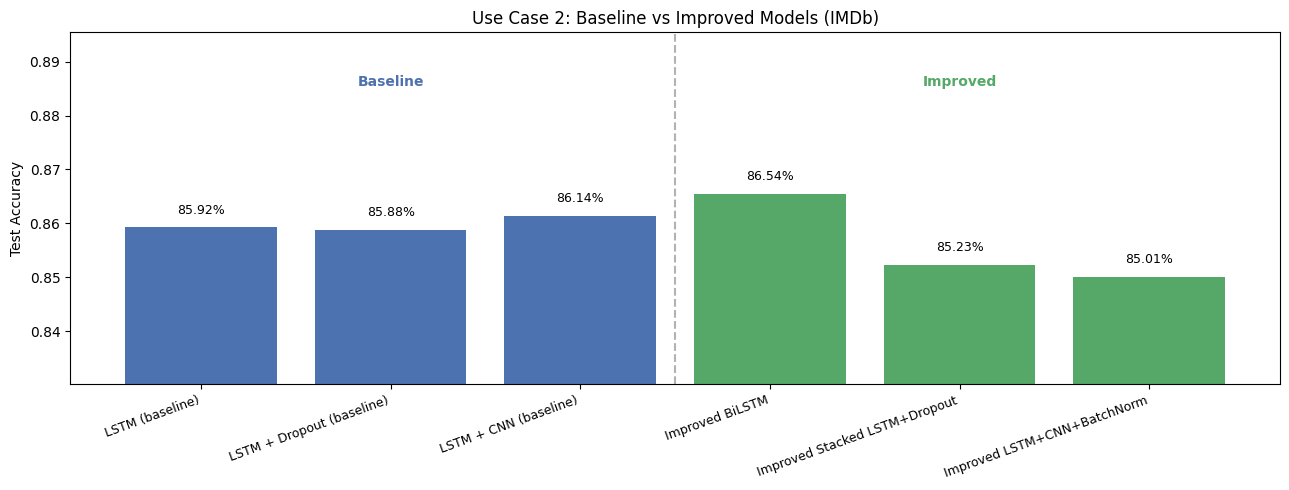


=== Summary ===
  (baseline)   LSTM (baseline): 85.92%
  (baseline)   LSTM + Dropout (baseline): 85.88%
  (baseline)   LSTM + CNN (baseline): 86.14%
  (improved)   Improved BiLSTM: 86.54%
  (improved)   Improved Stacked LSTM+Dropout: 85.23%
  (improved)   Improved LSTM+CNN+BatchNorm: 85.01%


In [54]:
improved_results = {
    'Improved BiLSTM':               acc_imp1,
    'Improved Stacked LSTM+Dropout': acc_imp2,
    'Improved LSTM+CNN+BatchNorm':   acc_imp3,
}

all_results = {**baseline_results, **improved_results}
labels_all  = list(all_results.keys())
accs_all    = list(all_results.values())
colors_all  = ['#4C72B0'] * len(baseline_results) + ['#55A868'] * len(improved_results)

fig, ax = plt.subplots(figsize=(13, 5))
bars = ax.bar(range(len(labels_all)), accs_all, color=colors_all)
ax.set_xticks(range(len(labels_all)))
ax.set_xticklabels(labels_all, rotation=20, ha='right', fontsize=9)
ax.set_ylim(min(accs_all) - 0.02, min(max(accs_all) + 0.03, 1.0))
ax.set_ylabel('Test Accuracy')
ax.set_title('Use Case 2: Baseline vs Improved Models (IMDb)')
ax.axvline(x=len(baseline_results) - 0.5, color='gray', linestyle='--', alpha=0.6)
ax.text(len(baseline_results) / 2 - 0.5, max(accs_all) + 0.02,
        'Baseline', ha='center', color='#4C72B0', fontsize=10, fontweight='bold')
ax.text(len(baseline_results) + len(improved_results) / 2 - 0.5, max(accs_all) + 0.02,
        'Improved', ha='center', color='#55A868', fontsize=10, fontweight='bold')
for bar, acc in zip(bars, accs_all):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.002,
            f'{acc*100:.2f}%', ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()

print("\n=== Summary ===")
for name, acc in all_results.items():
    tag = "(improved)" if name in improved_results else "(baseline)"
    print(f"  {tag:12s} {name}: {acc*100:.2f}%")